# 14주차 강의자 시연 — 지하철 혼잡도 분석 프로젝트

완성 코드 및 실제 실행 결과입니다. 학생용과 별도 파일입니다.

## 1. 준비 및 데이터 읽기
CPU 런타임을 사용합니다. 자동 다운로드가 실패하면 Drive에서 CSV를 내려받아 업로드하세요.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
path = Path('subway_project.csv')
if not path.exists():
    try:
        pd.read_csv('https://raw.githubusercontent.com/itlects/2026-2_ai-data/main/week14/subway_project.csv').to_csv(path,index=False,encoding='utf-8-sig')
    except Exception:
        from google.colab import files
        files.upload()
df = pd.read_csv(path)
print(df.shape)
print(df.head().to_string(index=False))

(1662, 7)
day  line  station_id station direction  morning  evening
 평일     1         158     청량리        상선     18.6     65.1
 평일     1         157     제기동        상선     21.4     72.6
 평일     1         156     신설동        상선     23.3     73.1
 평일     1         159     동묘앞        상선     27.0     74.1
 평일     1         155     동대문        상선     30.3     87.0


## 2. 데이터 점검
결측값과 중복 행을 확인합니다. 혼잡도 100% 초과는 정원 기준 혼잡도를 나타내므로 임의 제거하지 않습니다. 0은 원자료 값으로 유지하되 의미 확인이 필요합니다.

day           0
line          0
station_id    0
station       0
direction     0
morning       0
evening       0
dtype: int64
Duplicates: 0
     morning  evening
day                  
일요일    13.33    29.46
토요일    23.77    42.19
평일     59.94    59.30


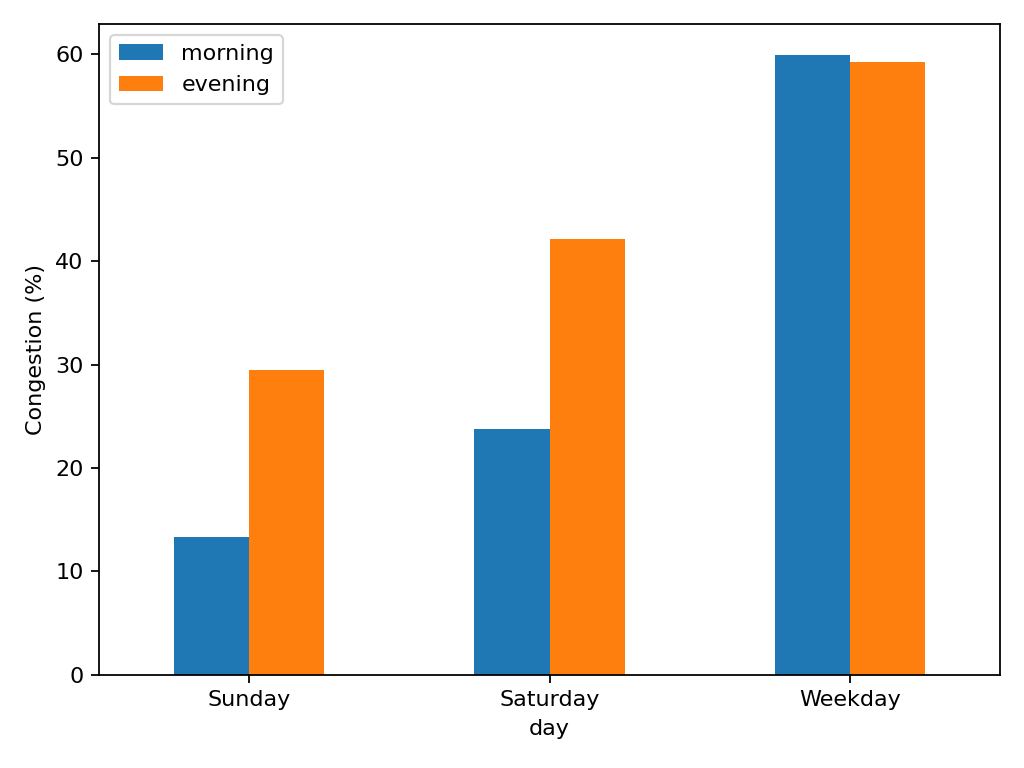

In [2]:
print(df.isna().sum())
print('Duplicates:',df.duplicated().sum())
df = df.dropna().drop_duplicates().reset_index(drop=True)
print(df.groupby('day')[['morning','evening']].mean().round(2))
ax=df.groupby('day')[['morning','evening']].mean().plot.bar(rot=0)
ax.set_ylabel('Congestion (%)')
ax.set_xticks(range(len(ax.get_xticks())), ['Sunday','Saturday','Weekday'])
plt.tight_layout(); plt.savefig('day_comparison.png',dpi=160); plt.show()

## 3. 분석 문제와 평가 분리
오전 8시 혼잡도와 요일·호선·방향으로 오후 6시 혼잡도를 추정합니다. 같은 역번호가 학습·평가에 섞이지 않도록 그룹 분리합니다.

In [3]:
X = pd.get_dummies(df[['day','line','direction','morning']],columns=['day','line','direction'],dtype=int)
y = df['evening']
split = GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=42)
train,test = next(split.split(X,y,groups=df['station_id']))
assert not set(df.iloc[train].station_id) & set(df.iloc[test].station_id)
print('Train/Test:',len(train),len(test))
print('Stations:',df.iloc[train].station_id.nunique(),df.iloc[test].station_id.nunique())

Train/Test: 1326 336
Stations: 224 56


## 4. 기준선과 AI 모델
훈련 데이터 평균을 항상 예측하는 기준선과 여러 의사결정나무를 결합하는 랜덤 포레스트를 같은 평가 집합에서 비교합니다. MAE는 실제값과 예측값의 절대 차이 평균이며 단위는 %p입니다.

Baseline         20.43
Random forest    13.48
dtype: float64


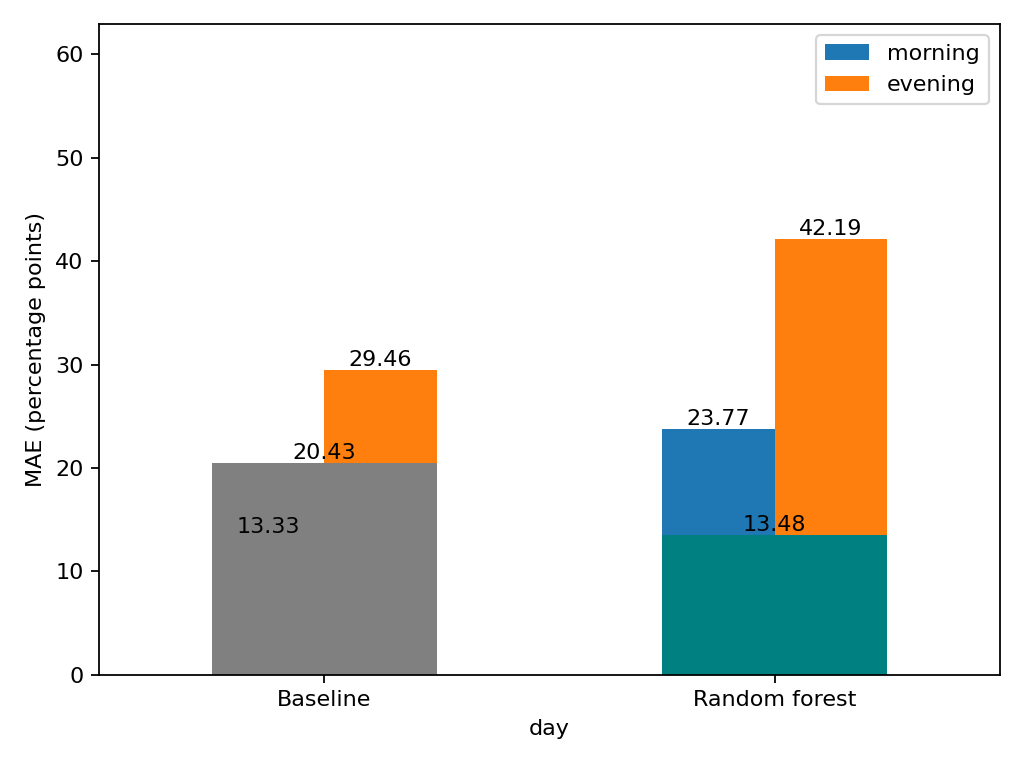

In [4]:
baseline = DummyRegressor(strategy='mean').fit(X.iloc[train],y.iloc[train])
model = RandomForestRegressor(n_estimators=100,min_samples_leaf=5,random_state=42,n_jobs=1).fit(X.iloc[train],y.iloc[train])
base = baseline.predict(X.iloc[test])
pred = model.predict(X.iloc[test])
scores = pd.Series({'Baseline':mean_absolute_error(y.iloc[test],base),'Random forest':mean_absolute_error(y.iloc[test],pred)})
print(scores.round(2))
ax=scores.plot.bar(color=['gray','teal'],rot=0)
ax.set_ylabel('MAE (percentage points)')
for bar in ax.containers: ax.bar_label(bar,fmt='%.2f')
plt.tight_layout(); plt.savefig('model_comparison.png',dpi=160); plt.show()

## 5. 오차와 활용
산점도에서 대각선이 정확한 예측입니다. 과소추정·과대추정 사례를 확인하고 혼잡 안내 서비스의 참고자료로 활용할 수 있는지 판단합니다.

station day  evening  prediction  error
     일원  평일     21.8       89.03  67.23
    독립문  평일    117.0       51.28 -65.72
     역삼  평일    126.5       66.39 -60.11
    남태령  평일    101.9       46.55 -55.35
     석촌  평일    125.1       70.45 -54.65


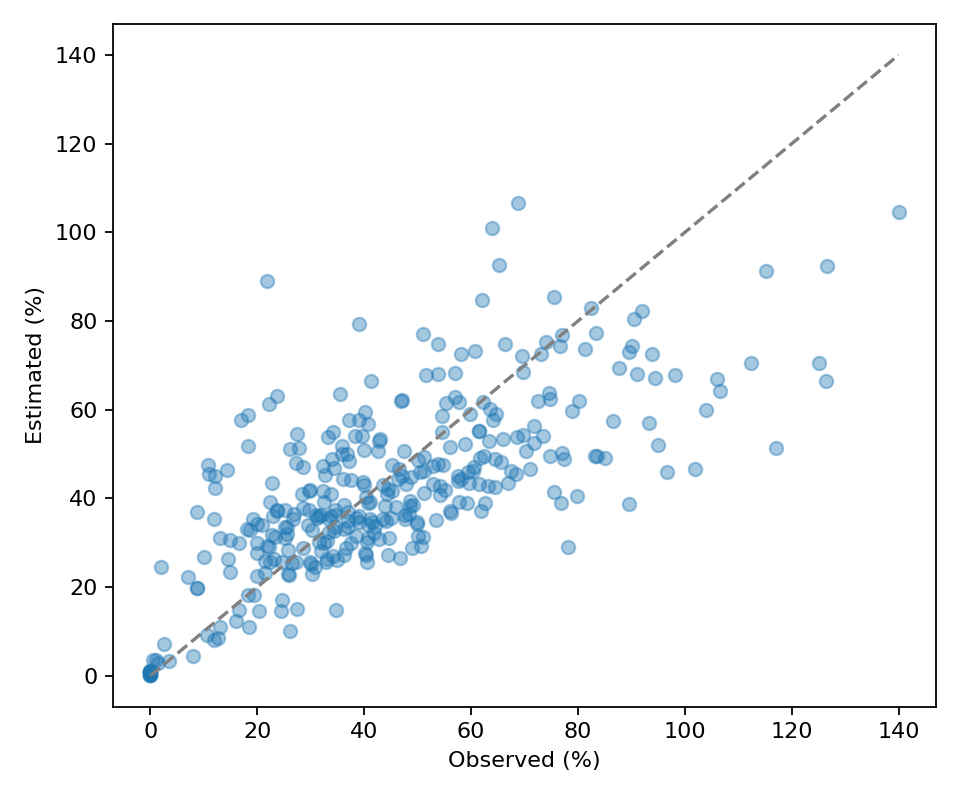

In [5]:
result = df.iloc[test].copy()
result['prediction'] = pred.round(2)
result['error'] = (result['prediction']-result['evening']).round(2)
result['absolute_error'] = result['error'].abs()
print(result.nlargest(5,'absolute_error')[['station','day','evening','prediction','error']].to_string(index=False))
plt.figure(figsize=(6,5)); plt.scatter(result.evening,result.prediction,alpha=.4)
limit=max(result.evening.max(),result.prediction.max())
plt.plot([0,limit],[0,limit],'--',color='gray'); plt.xlabel('Observed (%)'); plt.ylabel('Estimated (%)')
plt.tight_layout(); plt.savefig('prediction_scatter.png',dpi=160); plt.show()
result.to_csv('project_predictions.csv',index=False,encoding='utf-8-sig')
scores.rename('MAE').to_csv('project_scores.csv')

## 6. 결과 제출
Colab의 파일 탭에서 결과를 내려받습니다. 자신의 해석은 노트북 마지막에 작성합니다.

In [6]:
import zipfile
with zipfile.ZipFile('project_results.zip','w') as z:
    for name in ['day_comparison.png','model_comparison.png','prediction_scatter.png','project_predictions.csv','project_scores.csv']:
        z.write(name)
print('project_results.zip ready')

project_results.zip ready


## 시연 해설
평가역의 결과는 같은 역을 학습하지 않은 조건입니다. 평균보다 AI의 오차가 낮은지 확인하지만, 집계 데이터이므로 특정 날짜 미래 예측이나 인과관계 증명으로 해석하지 않습니다. 0값 의미, 다른 분기 비교, 실제 날짜별 데이터 확보를 후속 제안으로 설명합니다.